# Week 5 · Day 4 — Charts and the SQL bridge

Timur's request: *a monthly figure pack as PNGs for the board deck.* Every chart below runs from `nur.db` through `pd.read_sql`
and is saved into `figures/`. Change the title when the finding changes; the code stays.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
DATA = Path("..")              # this notebook lives in data/python/, so ".." is the data/ folder
AS_OF = pd.Timestamp("2026-10-01")
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
con = sqlite3.connect(DATA / "raw" / "nur.db")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
bn = FuncFormatter(lambda x, _: f"{x/1e9:,.0f} bn")
sns.set_theme(style="whitegrid", context="talk")
GREY, BLUE, RED = "#9ca3af", "#1d4ed8", "#dc2626"

## The bridge: any week-3 query becomes a DataFrame

In [2]:
monthly = pd.read_sql("""
    SELECT strftime('%Y-%m', disbursed_at) AS month, COUNT(*) AS loans, SUM(principal) AS disbursed
    FROM loans WHERE disbursed_at < '2026-10-01' GROUP BY 1 ORDER BY 1""", con)
monthly["ma3"] = monthly["disbursed"].rolling(3).mean()
monthly.tail()

,month,loans,disbursed,ma3
28,2026-05,377,18531830000,1.869474e+10
29,2026-06,373,16050300000,1.749237e+10
30,2026-07,367,20693870000,1.842533e+10
31,2026-08,358,22290210000,1.967813e+10
32,2026-09,361,17015490000,1.999986e+10


## Figure 1 — monthly disbursements with a 3-month moving average

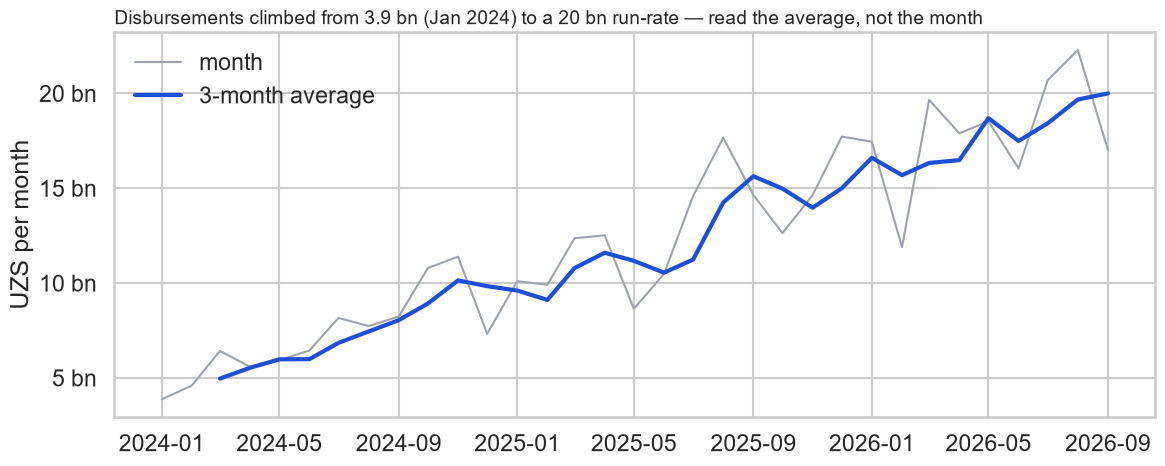

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))
x = pd.to_datetime(monthly["month"])
ax.plot(x, monthly["disbursed"], color=GREY, lw=1.5, label="month")
ax.plot(x, monthly["ma3"], color=BLUE, lw=3, label="3-month average")
ax.yaxis.set_major_formatter(bn)
ax.set_title("Disbursements climbed from 3.9 bn (Jan 2024) to a 20 bn run-rate — read the average, not the month", loc="left", fontsize=14)
ax.set_xlabel(""); ax.set_ylabel("UZS per month"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "01_disbursements_ma3.png", dpi=150)

## Figure 2 — outstanding mix by product (barh, % labels)

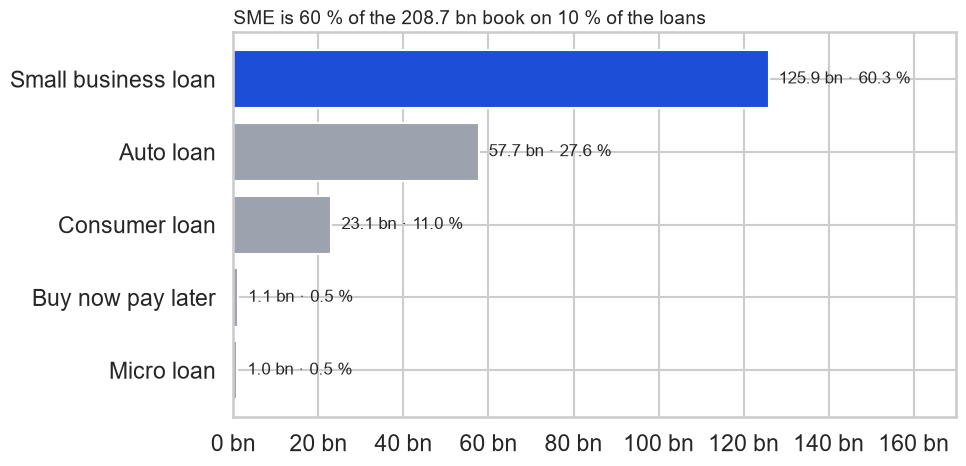

In [4]:
mix = pd.read_sql("""
    SELECT p.name AS product, SUM(i.principal_due) AS outstanding
    FROM installments i JOIN loans l ON l.loan_id = i.loan_id JOIN products p ON p.product_id = l.product_id
    WHERE i.due_date > '2026-10-01' GROUP BY 1 ORDER BY 2""", con)
mix["share"] = 100 * mix["outstanding"] / mix["outstanding"].sum()
fig, ax = plt.subplots(figsize=(10, 5))
colors = [BLUE if s == mix["share"].max() else GREY for s in mix["share"]]
ax.barh(mix["product"], mix["outstanding"], color=colors)
for y, (v, s) in enumerate(zip(mix["outstanding"], mix["share"])):
    ax.text(v, y, f"  {v/1e9:,.1f} bn · {s:.1f} %", va="center", fontsize=12)
ax.xaxis.set_major_formatter(bn); ax.set_xlim(0, mix["outstanding"].max() * 1.35)
ax.set_title("SME is 60 % of the 208.7 bn book on 10 % of the loans", loc="left", fontsize=14)
fig.tight_layout(); fig.savefig(FIG / "02_outstanding_mix.png", dpi=150)

## Figure 3 — DPD buckets (90+ in red)

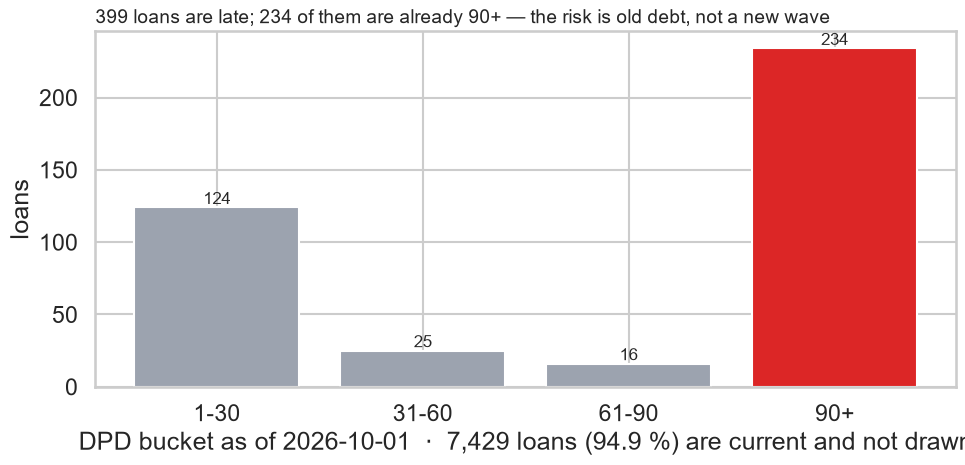

In [5]:
ls = pd.read_csv(DATA / "excel" / "loans_status.csv")
order = ["0", "1-30", "31-60", "61-90", "90+"]
b = ls["bucket"].value_counts().reindex(order)
late = b.drop("0")                       # bars start at zero, so the 7 429 current loans go in the subtitle, not on the axis
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(late.index, late.values, color=[RED if k == "90+" else GREY for k in late.index])
for i, v in enumerate(late.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=12)
ax.set_title("399 loans are late; 234 of them are already 90+ — the risk is old debt, not a new wave", loc="left", fontsize=14)
ax.set_ylabel("loans"); ax.set_xlabel(f"DPD bucket as of 2026-10-01  ·  {b['0']:,} loans ({100*b['0']/b.sum():.1f} %) are current and not drawn")
fig.tight_layout(); fig.savefig(FIG / "03_dpd_buckets.png", dpi=150)

## Figure 4 — vintage heatmap (cohort × months on book, ever-30+ %) — week 3's CTE chain, unchanged

mob,1,2,3,4,5,6
cohort,,,,,,
2025-01,0.66,0.66,1.99,2.65,3.31,5.30
2025-02,1.30,1.95,3.90,7.14,7.79,7.79
2025-03,2.48,3.11,5.59,7.45,8.07,9.94
2025-04,2.31,2.89,2.89,4.05,5.78,6.94
2025-05,1.08,3.24,5.41,5.95,6.49,7.03
2025-06,0.00,2.94,3.43,4.41,5.88,6.37
2025-07,0.00,1.69,4.64,5.91,6.33,7.17
2025-08,2.38,3.81,3.81,5.24,5.71,6.67
2025-09,1.55,4.15,5.70,6.22,7.25,7.25


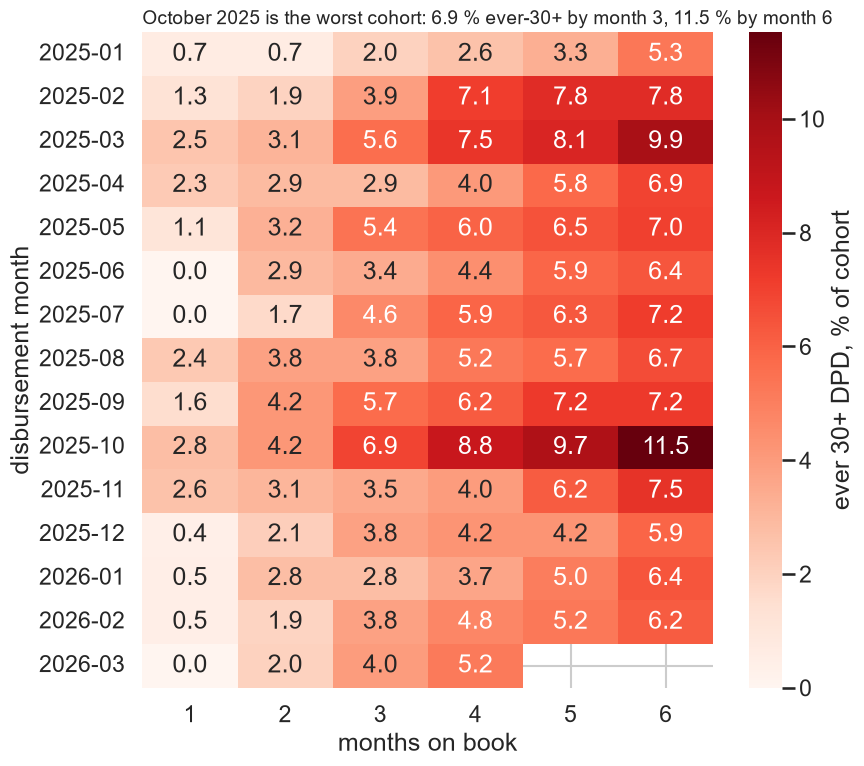

In [6]:
VINTAGE_SQL = """
WITH pc AS (SELECT * FROM (SELECT *, ROW_NUMBER() OVER (PARTITION BY installment_id, paid_at, amount ORDER BY payment_id) rn FROM payments) WHERE rn = 1),
inst AS (SELECT i.loan_id, i.installment_no, i.due_date, i.total_due,
           COALESCE(SUM(CASE WHEN p.paid_at <= date(i.due_date, '+30 days') THEN p.amount END), 0) AS paid_by_30
         FROM installments i LEFT JOIN pc p ON p.installment_id = i.installment_id
         WHERE i.installment_no <= 6 AND date(i.due_date, '+30 days') <= '2026-10-01'
         GROUP BY i.installment_id, i.loan_id, i.installment_no, i.due_date, i.total_due),
flag AS (SELECT loan_id, installment_no, CASE WHEN paid_by_30 < total_due THEN 1 ELSE 0 END AS late30 FROM inst),
ever AS (SELECT loan_id, installment_no, MAX(late30) OVER (PARTITION BY loan_id ORDER BY installment_no) AS ever30 FROM flag),
base AS (SELECT loan_id, strftime('%Y-%m', disbursed_at) AS cohort FROM loans
         WHERE term_months >= 6 AND disbursed_at >= '2025-01-01' AND disbursed_at < '2026-04-01'),
cells AS (SELECT b.cohort, e.installment_no AS mob, COUNT(*) AS observed, SUM(e.ever30) AS ever,
                 (SELECT COUNT(*) FROM base x WHERE x.cohort = b.cohort) AS cohort_size
          FROM base b JOIN ever e ON e.loan_id = b.loan_id GROUP BY b.cohort, e.installment_no)
SELECT cohort, mob, ROUND(100.0 * ever / observed, 2) AS ever30_pct FROM cells WHERE observed = cohort_size ORDER BY cohort, mob"""
vint = pd.read_sql(VINTAGE_SQL, con).pivot(index="cohort", columns="mob", values="ever30_pct")
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(vint, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "ever 30+ DPD, % of cohort"}, ax=ax)
ax.set_title("October 2025 is the worst cohort: 6.9 % ever-30+ by month 3, 11.5 % by month 6", loc="left", fontsize=14)
ax.set_xlabel("months on book"); ax.set_ylabel("disbursement month")
fig.tight_layout(); fig.savefig(FIG / "04_vintage_heatmap.png", dpi=150)
vint

## Figure 5 — roll-rate matrix 1 Sep → 1 Oct 2026 (FULL OUTER JOIN needs SQLite ≥ 3.39 — check `sqlite3.sqlite_version`)

to_bucket,0,1-30,31-60,61-90,90+
from_bucket,,,,,
0,24,117,0,0,0
1-30,97,6,25,0,0
31-60,6,1,0,16,0
61-90,0,0,0,0,17
90+,0,0,0,0,217


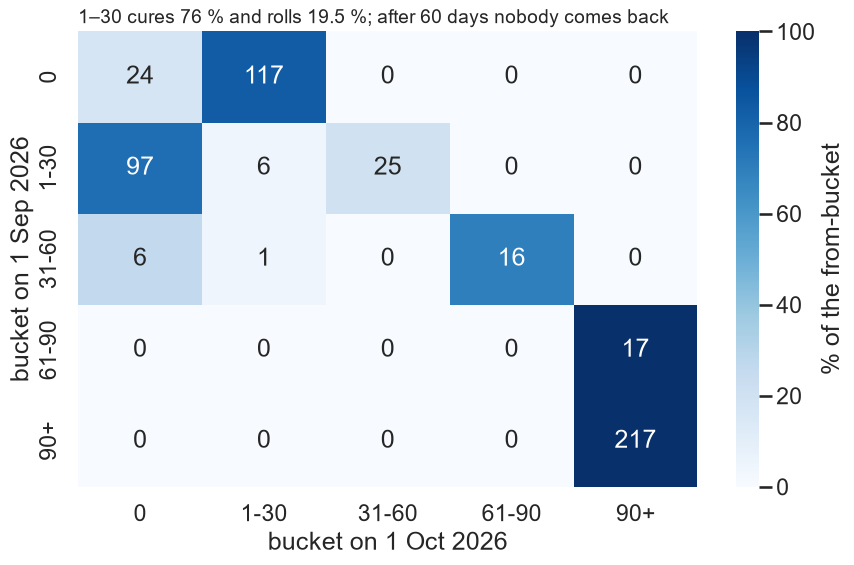

In [7]:
SNAP = """SELECT i.loan_id, i.due_date FROM installments i
  LEFT JOIN (SELECT * FROM (SELECT *, ROW_NUMBER() OVER (PARTITION BY installment_id, paid_at, amount ORDER BY payment_id) rn FROM payments) WHERE rn = 1) p
    ON p.installment_id = i.installment_id AND p.paid_at <= '{d}'
  WHERE i.due_date <= '{d}'
  GROUP BY i.installment_id, i.loan_id, i.due_date, i.total_due HAVING COALESCE(SUM(p.amount), 0) < i.total_due"""
BUCKET = "CASE WHEN {c} = 0 THEN '0' WHEN {c} <= 30 THEN '1-30' WHEN {c} <= 60 THEN '31-60' WHEN {c} <= 90 THEN '61-90' ELSE '90+' END"
ROLL_SQL = f"""
WITH u0 AS ({SNAP.format(d='2026-09-01')}),
d0 AS (SELECT loan_id, CAST(julianday('2026-09-01') - julianday(MIN(due_date)) AS INTEGER) AS dpd FROM u0 GROUP BY loan_id),
u1 AS ({SNAP.format(d='2026-10-01')}),
d1 AS (SELECT loan_id, CAST(julianday('2026-10-01') - julianday(MIN(due_date)) AS INTEGER) AS dpd FROM u1 GROUP BY loan_id),
j AS (SELECT COALESCE(a.loan_id, b.loan_id) AS loan_id, COALESCE(a.dpd, 0) AS dpd0, COALESCE(b.dpd, 0) AS dpd1
      FROM d0 a FULL OUTER JOIN d1 b ON a.loan_id = b.loan_id)
SELECT {BUCKET.format(c='dpd0')} AS from_bucket, {BUCKET.format(c='dpd1')} AS to_bucket, COUNT(*) AS loans FROM j GROUP BY 1, 2"""
roll = pd.read_sql(ROLL_SQL, con).pivot(index="from_bucket", columns="to_bucket", values="loans").reindex(index=order, columns=order).fillna(0).astype(int)
roll_pct = roll.div(roll.sum(axis=1), axis=0).mul(100)
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(roll_pct, annot=roll, fmt="d", cmap="Blues", cbar_kws={"label": "% of the from-bucket"}, ax=ax)
ax.set_title("1–30 cures 76 % and rolls 19.5 %; after 60 days nobody comes back", loc="left", fontsize=14)
ax.set_xlabel("bucket on 1 Oct 2026"); ax.set_ylabel("bucket on 1 Sep 2026")
fig.tight_layout(); fig.savefig(FIG / "05_roll_rate.png", dpi=150)
roll

## TODO — your sixth figure
Pick one: top-5 branches by 2026 disbursement (barh), or the collection rate by due month (line, September marked). Finding in the title; save it as `06_*.png`.

In [8]:
# your code here

In [9]:
sorted(p.name for p in FIG.glob("*.png"))

['01_disbursements_ma3.png',
 '02_outstanding_mix.png',
 '03_dpd_buckets.png',
 '04_vintage_heatmap.png',
 '05_roll_rate.png']